# rock paper scissors

image classifier trained on Teachable Machine (image project, 3 classes: Rock, Paper, Scissors), exported as Tensorflow -> Keras.

the export gives two files that go next to this notebook:
- `keras_model.h5` - the trained model
- `labels.txt` - class names, one per line like `0 Rock`

environment from the lecture:
```
conda create -n tm_model python=3.10
conda activate tm_model
pip install tensorflow==2.15.0
pip install pillow numpy
```

In [1]:
from keras.models import load_model
from PIL import Image, ImageOps
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress=True)

## load the model

In [2]:
model = load_model("keras_model.h5", compile=False)
class_names = open("labels.txt", "r").readlines()
print(class_names)
model.summary()

['0 Rock\n', '1 Paper\n', '2 Scissors\n']
Model: "sequential_4"


_________________________________________________________________


 Layer (type)                Output Shape              Param #   


 sequential_1 (Sequential)   (None, 1280)              410208    


 sequential_3 (Sequential)   (None, 3)                 128400    


Total params: 538608 (2.05 MB)


Trainable params: 524528 (2.00 MB)


Non-trainable params: 14080 (55.00 KB)


_________________________________________________________________


## classify a new image

teachable machine models take 224x224 RGB images scaled to -1..1

In [3]:
def classify(image_path):
    # Teachable machine input: 1 image, 224x224, 3 channels
    data = np.ndarray(shape=(1, 224, 224, 3), dtype=np.float32)

    image = Image.open(image_path).convert("RGB")
    image = ImageOps.fit(image, (224, 224), Image.Resampling.LANCZOS)
    image_array = np.asarray(image)
    data[0] = (image_array.astype(np.float32) / 127.5) - 1

    # forward propagation through the trained model
    prediction = model.predict(data, verbose=0)
    index = np.argmax(prediction)
    class_name = class_names[index].strip()[2:]
    confidence_score = prediction[0][index]

    plt.imshow(image)
    plt.title(f"{class_name} ({confidence_score:.2f})")
    plt.axis('off')
    plt.show()
    print("Class:", class_name)
    print("Confidence Score:", confidence_score)
    return class_name

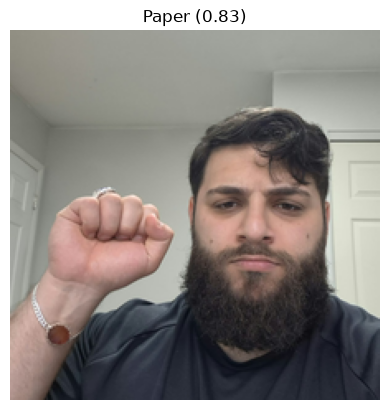

Class: Paper
Confidence Score: 0.8278043


'Paper'

In [4]:
classify("test_images/rock_1.jpg")

## all test images

none of these were used for training. `_1` images were taken with my phone, the rest with the laptop webcam. the file name says what the hand is showing, so each prediction can be checked.

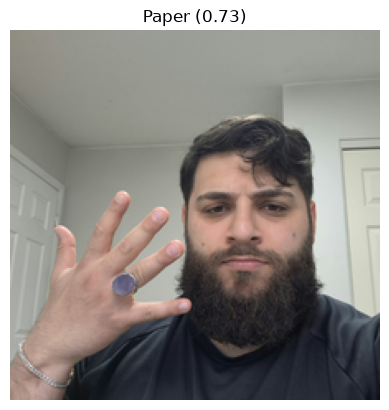

Class: Paper
Confidence Score: 0.73415786
Success: paper_1.jpg is Paper and is recognized as Paper.



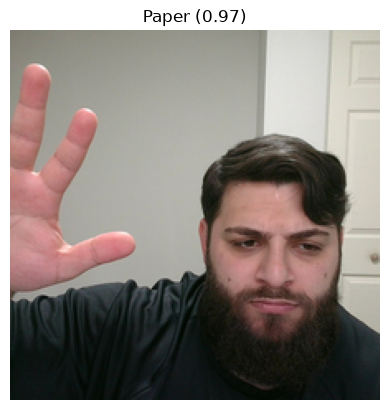

Class: Paper
Confidence Score: 0.967138
Success: paper_2.jpg is Paper and is recognized as Paper.



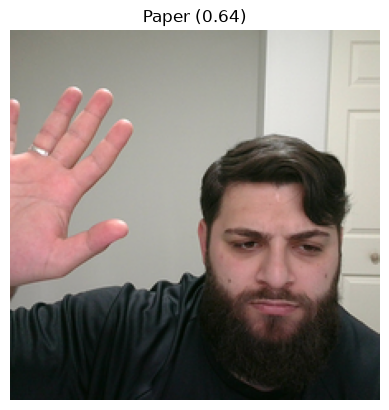

Class: Paper
Confidence Score: 0.63895106
Success: paper_3.jpg is Paper and is recognized as Paper.



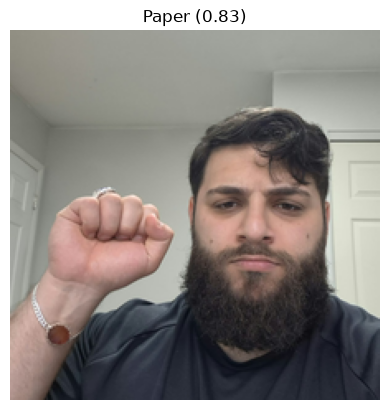

Class: Paper
Confidence Score: 0.8278043
Fail: rock_1.jpg is Rock but the inference result is Paper.



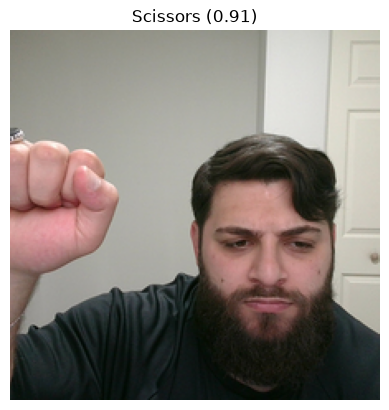

Class: Scissors
Confidence Score: 0.91445786
Fail: rock_2.jpg is Rock but the inference result is Scissors.



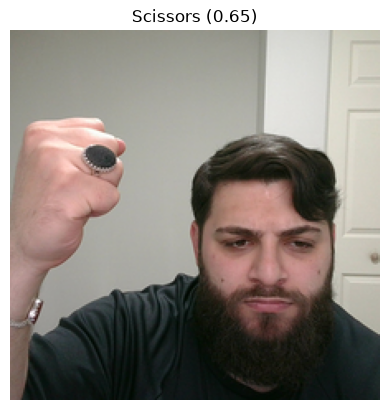

Class: Scissors
Confidence Score: 0.6470369
Fail: rock_3.jpg is Rock but the inference result is Scissors.



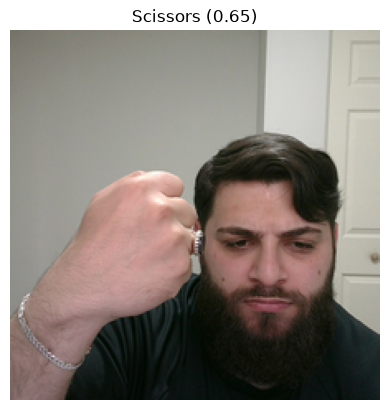

Class: Scissors
Confidence Score: 0.654397
Fail: rock_4.jpg is Rock but the inference result is Scissors.



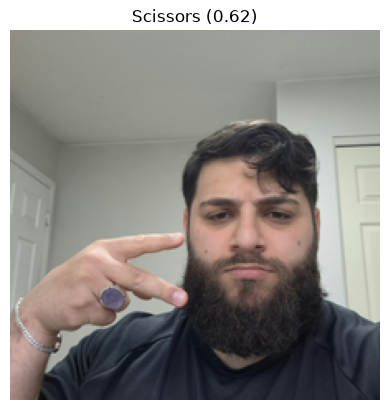

Class: Scissors
Confidence Score: 0.61588436
Success: scissors_1.jpg is Scissors and is recognized as Scissors.



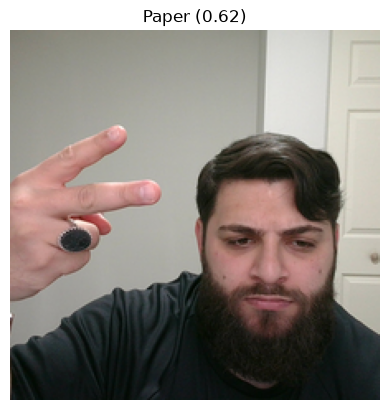

Class: Paper
Confidence Score: 0.61820537
Fail: scissors_2.jpg is Scissors but the inference result is Paper.



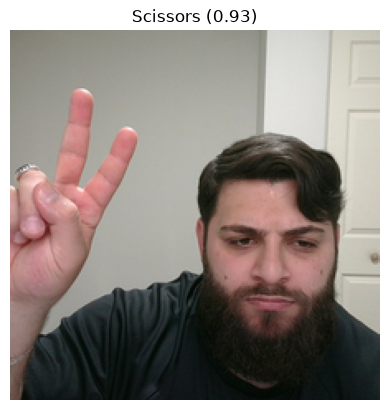

Class: Scissors
Confidence Score: 0.92936474
Success: scissors_3.jpg is Scissors and is recognized as Scissors.



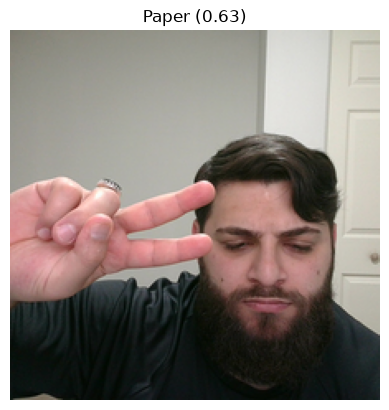

Class: Paper
Confidence Score: 0.6299996
Fail: scissors_4.jpg is Scissors but the inference result is Paper.

5 / 11 correct


In [5]:
# Classify every image in test_images/ and compare with the gesture in the file name
import os
correct, total = 0, 0
for file_name in sorted(os.listdir("test_images")):
    if not file_name.lower().endswith((".jpg", ".jpeg", ".png")):
        continue
    truth = file_name.split("_")[0].capitalize()
    result = classify(os.path.join("test_images", file_name))
    total += 1
    if result == truth:
        correct += 1
        print(f"Success: {file_name} is {truth} and is recognized as {result}.")
    else:
        print(f"Fail: {file_name} is {truth} but the inference result is {result}.")
    print()
print(f"{correct} / {total} correct")

## results

5 out of 11 correct. paper got all 3, scissors got 2 of 4, and rock got 0 of 4 (it gets called paper or scissors). each class was recorded as one short webcam burstso the training frames are almost the same picture over and over in terms of the position and distance.  the model learned that one position instead of the hand shape, so new photos with the hand somewhere else get mixed up i think if i was to record more varied samples it would probably fix it